## Imports and global settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (roc_auc_score, f1_score, precision_score,
                             recall_score, average_precision_score)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_classif
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 4)

RANDOM_STATE = 42
TEST_SIZE = 0.2          # hold-out fraction for both strategies
N_TOP_FEATURES = 30      # select top 30 features via mutual information

## Helper functions for temporal-aware splitting and evaluation

In [2]:
def temporal_split(X, y, time_vals, test_size=TEST_SIZE):
    """
    Chronological split: sort by time, test = last test_size fraction.
    """
    idx_sorted = np.argsort(time_vals)
    X_sorted = X.iloc[idx_sorted].reset_index(drop=True)
    y_sorted = y.iloc[idx_sorted].reset_index(drop=True)
    n_test = int(len(X_sorted) * test_size)
    X_train, X_test = X_sorted[:-n_test], X_sorted[-n_test:]
    y_train, y_test = y_sorted[:-n_test], y_sorted[-n_test:]
    return X_train, X_test, y_train, y_test

def random_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE):
    """
    Standard random train/test split (no time order).
    """
    return train_test_split(X, y, test_size=test_size,
                            random_state=random_state, shuffle=True)

def run_experiment(X, y, time_vals, split_func, split_kwargs, top_k=N_TOP_FEATURES):
    """
    Complete pipeline with zero leakage:
      1. Split data
      2. Impute missing values (fit on train)
      3. Select top_k features via mutual information (on train)
      4. Scale (fit on train)
      5. Train three classifiers, evaluate on test
    Returns: dict of model->metric dict.
    """
    # ----- 1. Split -----
    X_train, X_test, y_train, y_test = split_func(X, y, **split_kwargs)

    # ----- 2. Imputation -----
    # Only numeric columns are kept; drop columns that are entirely NaN in train
    numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
    X_train_num = X_train[numeric_cols].copy()
    X_test_num  = X_test[numeric_cols].copy()

    # Drop columns that are all NaN in train (cannot impute)
    valid_cols = [c for c in numeric_cols if X_train_num[c].notna().any()]
    X_train_num = X_train_num[valid_cols]
    X_test_num  = X_test_num[valid_cols]

    imputer = SimpleImputer(strategy='median')
    X_train_imp = pd.DataFrame(imputer.fit_transform(X_train_num),
                               columns=valid_cols)
    X_test_imp  = pd.DataFrame(imputer.transform(X_test_num),
                               columns=valid_cols)

    # ----- 3. Feature selection (Mutual Information, train only) -----
    mi_scores = mutual_info_classif(X_train_imp, y_train, random_state=RANDOM_STATE)
    mi_df = pd.DataFrame({'feature': valid_cols, 'mi': mi_scores})
    mi_df = mi_df.sort_values('mi', ascending=False)
    selected_features = mi_df.head(top_k)['feature'].tolist()
    print(f"   Selected {len(selected_features)} features (top 5): {selected_features[:5]} ...")

    X_train_sel = X_train_imp[selected_features]
    X_test_sel  = X_test_imp[selected_features]

    # ----- 4. Scaling -----
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train_sel)
    X_test_s  = scaler.transform(X_test_sel)

    # ----- 5. Modelling -----
    models = {
        'Logistic Regression': LogisticRegression(max_iter=2000,
                                                  random_state=RANDOM_STATE,
                                                  class_weight='balanced'),
        'Random Forest': RandomForestClassifier(n_estimators=100,
                                                random_state=RANDOM_STATE,
                                                n_jobs=-1),
        'XGBoost': XGBClassifier(n_estimators=100,
                                 random_state=RANDOM_STATE,
                                 use_label_encoder=False,
                                 eval_metric='logloss',
                                 verbosity=0)
    }

    results = {}
    for name, model in models.items():
        model.fit(X_train_s, y_train)
        y_pred = model.predict(X_test_s)
        y_proba = model.predict_proba(X_test_s)[:, 1]

        results[name] = {
            'AUROC': roc_auc_score(y_test, y_proba),
            'F1': f1_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred),
            'Recall': recall_score(y_test, y_pred),
            'AUC-PR': average_precision_score(y_test, y_proba)
        }
    return results

def print_results(res, title):
    print(f"\n{title}")
    for model, m in res.items():
        print(f"  {model}: AUROC={m['AUROC']:.4f}, F1={m['F1']:.4f}, "
              f"Precision={m['Precision']:.4f}, Recall={m['Recall']:.4f}, AUC-PR={m['AUC-PR']:.4f}")

# Dataset 1 – IEEE-CIS Fraud Detection

In [3]:
# Load training transaction data (has labels)
train_id = pd.read_csv("../../Dataset/ieee-fraud-detection/train_transaction.csv")

# Target and time column
target = 'isFraud'
time_col = 'TransactionDT'

# we don't need it ID column
df_raw = train_id.drop(columns=['TransactionID'])

print(f"Full dataset shape: {df_raw.shape}")
print(f"Fraud rate: {df_raw[target].mean():.4%}")

Full dataset shape: (590540, 393)
Fraud rate: 3.4990%


## Prepare raw feature matrix and target vector (no preprocessing!)

In [4]:
# We keep only numeric columns + target + time for splitting.
# The function run_experiment will handle further filtering inside.
X_all = df_raw.drop(columns=[target, time_col])  # raw features
y_all = df_raw[target]
time_all = df_raw[time_col].values

# Remove any columns that are not numeric (to make our work easier)
X_all = X_all.select_dtypes(include=[np.number])
print(f"Raw numeric feature count: {X_all.shape[1]}")

Raw numeric feature count: 377


## Run temporal split experiment (chronological)

In [5]:
print("=== TEMPORAL SPLIT (chronological) ===")
res_temp = run_experiment(X_all, y_all, time_all,
                          temporal_split, {'time_vals': time_all})

# Run random split experiment
print("\n=== RANDOM SPLIT (time-ignorant) ===")
res_rand = run_experiment(X_all, y_all, time_all,
                          random_split, {})

=== TEMPORAL SPLIT (chronological) ===
   Selected 30 features (top 5): ['addr2', 'V251', 'V247', 'V250', 'V245'] ...

=== RANDOM SPLIT (time-ignorant) ===
   Selected 30 features (top 5): ['V246', 'V258', 'V198', 'V149', 'V155'] ...


## Display and compare results

In [6]:
print_results(res_temp, "TEMPORAL SPLIT")
print_results(res_rand, "RANDOM SPLIT")

# Compute inflation (in %)
print("\n--- METRIC INFLATION (Random over Temporal) ---")
for metric in ['AUROC', 'F1', 'Precision', 'Recall', 'AUC-PR']:
    for model in res_temp:
        temp_val = res_temp[model][metric]
        rand_val = res_rand[model][metric]
        infl = 100 * (rand_val - temp_val) / temp_val
        print(f"{model:20s} | {metric:10s}: +{infl:6.1f}%")


TEMPORAL SPLIT
  Logistic Regression: AUROC=0.6933, F1=0.1912, Precision=0.1187, Recall=0.4911, AUC-PR=0.2822
  Random Forest: AUROC=0.6904, F1=0.3132, Precision=0.6904, Recall=0.2025, AUC-PR=0.2826
  XGBoost: AUROC=0.6935, F1=0.3174, Precision=0.7466, Recall=0.2015, AUC-PR=0.3034

RANDOM SPLIT
  Logistic Regression: AUROC=0.7078, F1=0.2147, Precision=0.1408, Recall=0.4519, AUC-PR=0.2862
  Random Forest: AUROC=0.7185, F1=0.3796, Precision=0.8382, Recall=0.2454, AUC-PR=0.3632
  XGBoost: AUROC=0.7250, F1=0.3676, Precision=0.8490, Recall=0.2346, AUC-PR=0.3622

--- METRIC INFLATION (Random over Temporal) ---
Logistic Regression  | AUROC     : +   2.1%
Random Forest        | AUROC     : +   4.1%
XGBoost              | AUROC     : +   4.5%
Logistic Regression  | F1        : +  12.3%
Random Forest        | F1        : +  21.2%
XGBoost              | F1        : +  15.8%
Logistic Regression  | Precision : +  18.6%
Random Forest        | Precision : +  21.4%
XGBoost              | Precision : 

## bar chart comparison

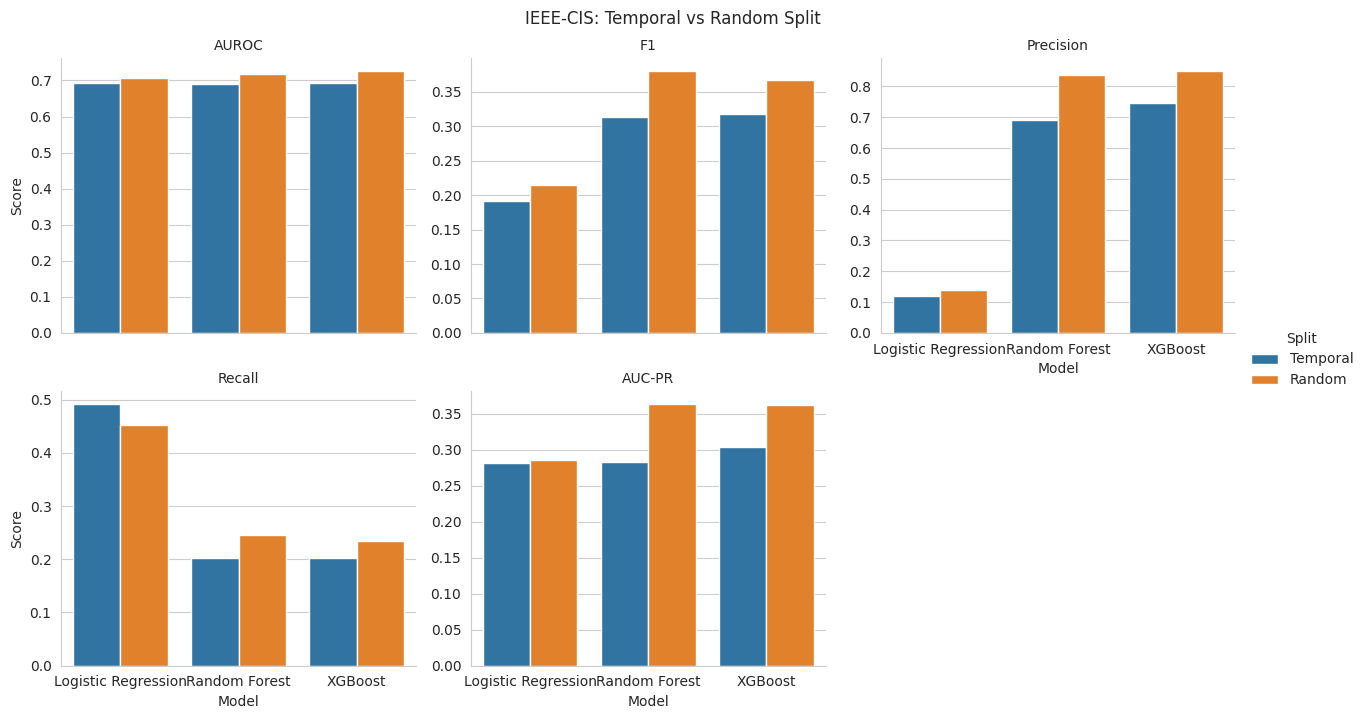

In [7]:
df_comp = []
for model in res_temp:
    for metric in ['AUROC', 'F1', 'Precision', 'Recall', 'AUC-PR']:
        df_comp.append({'Model': model, 'Metric': metric,
                        'Temporal': res_temp[model][metric],
                        'Random': res_rand[model][metric]})
df_comp = pd.DataFrame(df_comp)

# Melt for seaborn
df_plot = df_comp.melt(id_vars=['Model', 'Metric'],
                       value_vars=['Temporal', 'Random'],
                       var_name='Split', value_name='Value')

g = sns.catplot(data=df_plot, x='Model', y='Value', hue='Split',
                col='Metric', kind='bar', col_wrap=3,
                height=3.5, aspect=1.2, sharey=False)
g.set_titles("{col_name}")
g.set_ylabels("Score")
plt.suptitle("IEEE‑CIS: Temporal vs Random Split ", y=1.02)
plt.show()

# Dataset 2 – Sparkov synthetic fraud data (temporal)

In [8]:
# Load and combine train + test
sparkov_train = pd.read_csv("../../Dataset/SparkovGeneratedData/fraudTrain.csv")
sparkov_test  = pd.read_csv("../../Dataset/SparkovGeneratedData/fraudTest.csv")
df_sparkov_raw = pd.concat([sparkov_train, sparkov_test], ignore_index=True)

target_sp = 'is_fraud'
time_col_sp = 'trans_date_trans_time'

# Convert timestamp to ordinal for sorting
df_sparkov_raw[time_col_sp] = pd.to_datetime(df_sparkov_raw[time_col_sp])
df_sparkov_raw['time_ordinal'] = df_sparkov_raw[time_col_sp].map(pd.Timestamp.toordinal)

print(f"\nSparkov full dataset shape: {df_sparkov_raw.shape}")
print(f"Sparkov fraud rate: {df_sparkov_raw[target_sp].mean():.4%}")

# Drop non-numeric columns that cannot be used
non_numeric_cols = df_sparkov_raw.select_dtypes(exclude=[np.number]).columns.tolist()
drop_cols = [target_sp, time_col_sp, 'time_ordinal'] + non_numeric_cols
print(f"Dropping non-numeric columns: {non_numeric_cols}")

X_sp_all = df_sparkov_raw.drop(columns=drop_cols)
y_sp_all = df_sparkov_raw[target_sp]
time_sp_all = df_sparkov_raw['time_ordinal'].values

print(f"Sparkov numeric feature count: {X_sp_all.shape[1]}")


Sparkov full dataset shape: (1852394, 24)
Sparkov fraud rate: 0.5210%
Dropping non-numeric columns: ['trans_date_trans_time', 'merchant', 'category', 'first', 'last', 'gender', 'street', 'city', 'state', 'job', 'dob', 'trans_num']
Sparkov numeric feature count: 10


## Run temporal vs random split on Sparkov dataset

In [9]:
print("\n=== SPARKOV – TEMPORAL SPLIT (chronological) ===")
res_temp_sp = run_experiment(X_sp_all, y_sp_all, time_sp_all,
                             temporal_split, {'time_vals': time_sp_all})

print("\n=== SPARKOV – RANDOM SPLIT (time-ignorant) ===")
res_rand_sp = run_experiment(X_sp_all, y_sp_all, time_sp_all,
                             random_split, {})

print_results(res_temp_sp, "SPARKOV TEMPORAL SPLIT")
print_results(res_rand_sp, "SPARKOV RANDOM SPLIT")

print("\n--- SPARKOV METRIC INFLATION (Random over Temporal) ---")
for metric in ['AUROC', 'F1', 'Precision', 'Recall', 'AUC-PR']:
    for model in res_temp_sp:
        temp_val = res_temp_sp[model][metric]
        rand_val = res_rand_sp[model][metric]
        if temp_val == 0:
            if rand_val == 0:
                print(f"{model:20s} | {metric:10s}:   0 → 0  (no change)")
            else:
                print(f"{model:20s} | {metric:10s}:   0 → {rand_val:.4f}  (infinite inflation, model collapsed under temporal split)")
        else:
            infl = 100 * (rand_val - temp_val) / temp_val
            print(f"{model:20s} | {metric:10s}: +{infl:6.1f}%")


=== SPARKOV – TEMPORAL SPLIT (chronological) ===
   Selected 10 features (top 5): ['amt', 'unix_time', 'Unnamed: 0', 'lat', 'zip'] ...

=== SPARKOV – RANDOM SPLIT (time-ignorant) ===
   Selected 10 features (top 5): ['amt', 'unix_time', 'Unnamed: 0', 'long', 'lat'] ...

SPARKOV TEMPORAL SPLIT
  Logistic Regression: AUROC=0.8390, F1=0.1500, Precision=0.0832, Recall=0.7598, AUC-PR=0.1386
  Random Forest: AUROC=0.9009, F1=0.1418, Precision=0.2312, Recall=0.1023, AUC-PR=0.1370
  XGBoost: AUROC=0.7232, F1=0.2403, Precision=0.2152, Recall=0.2721, AUC-PR=0.0921

SPARKOV RANDOM SPLIT
  Logistic Regression: AUROC=0.8389, F1=0.1422, Precision=0.0784, Recall=0.7583, AUC-PR=0.1803
  Random Forest: AUROC=0.9754, F1=0.6213, Precision=0.8830, Recall=0.4793, AUC-PR=0.7137
  XGBoost: AUROC=0.8345, F1=0.3443, Precision=0.4648, Recall=0.2734, AUC-PR=0.2700

--- SPARKOV METRIC INFLATION (Random over Temporal) ---
Logistic Regression  | AUROC     : +  -0.0%
Random Forest        | AUROC     : +   8.3%
XGBo

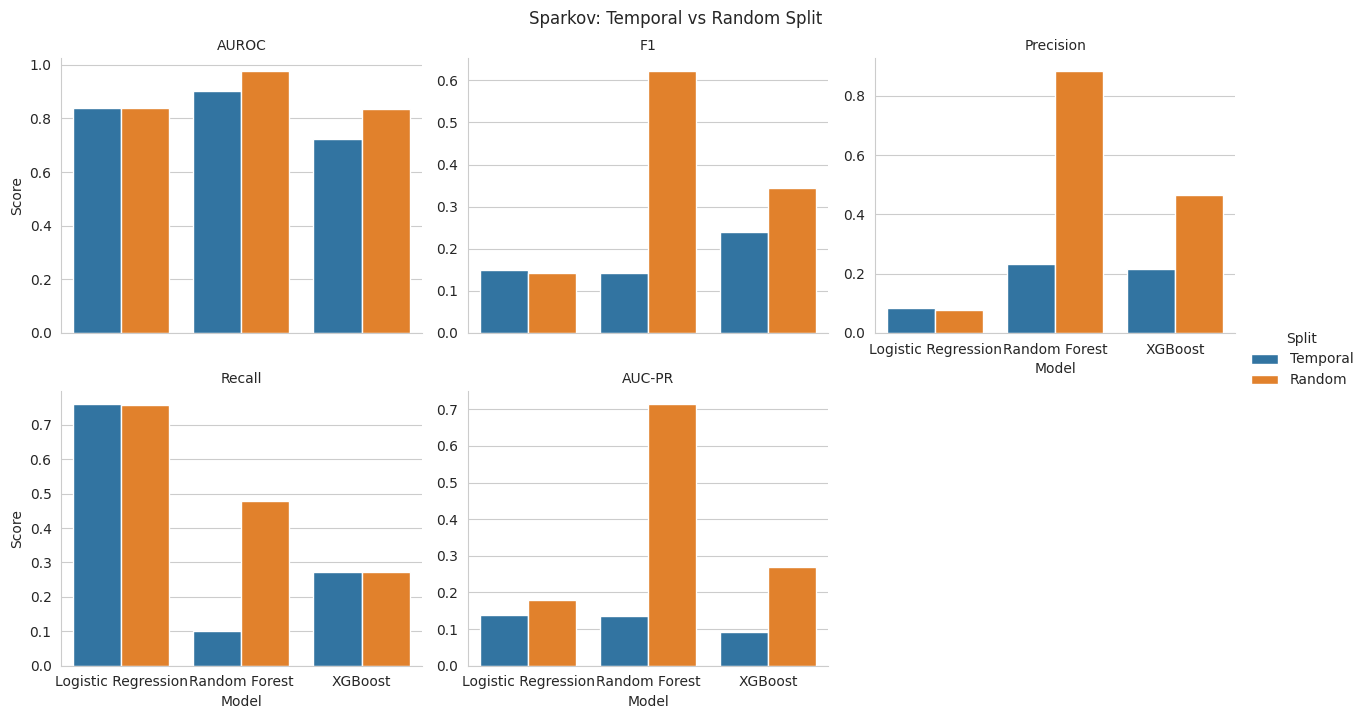

In [10]:
df_comp = []
for model in res_temp_sp:
    for metric in ['AUROC', 'F1', 'Precision', 'Recall', 'AUC-PR']:
        df_comp.append({'Model': model, 'Metric': metric,
                        'Temporal': res_temp_sp[model][metric],
                        'Random': res_rand_sp[model][metric]})
df_comp = pd.DataFrame(df_comp)

# Melt for seaborn
df_plot = df_comp.melt(id_vars=['Model', 'Metric'],
                       value_vars=['Temporal', 'Random'],
                       var_name='Split', value_name='Value')

g = sns.catplot(data=df_plot, x='Model', y='Value', hue='Split',
                col='Metric', kind='bar', col_wrap=3,
                height=3.5, aspect=1.2, sharey=False)
g.set_titles("{col_name}")
g.set_ylabels("Score")
plt.suptitle("Sparkov: Temporal vs Random Split", y=1.02)
plt.show()

## Aggregate all results into a single DataFrame for comparison

In [11]:
def results_to_df(res_temp, res_rand, dataset_name):
    rows = []
    for model in res_temp:
        rows.append({
            'Dataset': dataset_name, 'Model': model, 'Split': 'Temporal',
            'AUROC': res_temp[model]['AUROC'], 'F1': res_temp[model]['F1'],
            'Precision': res_temp[model]['Precision'],
            'Recall': res_temp[model]['Recall'],
            'AUC-PR': res_temp[model]['AUC-PR']
        })
        rows.append({
            'Dataset': dataset_name, 'Model': model, 'Split': 'Random',
            'AUROC': res_rand[model]['AUROC'], 'F1': res_rand[model]['F1'],
            'Precision': res_rand[model]['Precision'],
            'Recall': res_rand[model]['Recall'],
            'AUC-PR': res_rand[model]['AUC-PR']
        })
    return pd.DataFrame(rows)

df_ieee = results_to_df(res_temp, res_rand, 'IEEE-CIS')
df_sp   = results_to_df(res_temp_sp, res_rand_sp, 'Sparkov')
all_res = pd.concat([df_ieee, df_sp], ignore_index=True)

# Compute inflation table per (Dataset, Model, Metric)
# Use np.inf where temporal = 0 and random > 0
metrics_list = ['AUROC', 'F1', 'Precision', 'Recall', 'AUC-PR']
for metric in metrics_list:
    pivot = all_res.pivot_table(index=['Dataset', 'Model'],
                                columns='Split', values=metric)
    # Avoid division by zero: compute inflation manually
    infl_values = []
    for idx, row in pivot.iterrows():
        temp_v = row['Temporal']
        rand_v = row['Random']
        if temp_v == 0:
            infl_values.append(np.inf if rand_v > 0 else 0.0)
        else:
            infl_values.append(100 * (rand_v - temp_v) / temp_v)
    pivot['Inflation %'] = infl_values
    print(f"\n=== {metric} Inflation (Random vs Temporal) ===")
    # Replace inf with a string for display
    display_pivot = pivot.copy()
    display_pivot['Inflation %'] = display_pivot['Inflation %'].apply(
        lambda x: '∞' if np.isinf(x) else f"{x:.1f}"
    )
    print(display_pivot[['Temporal', 'Random', 'Inflation %']])


=== AUROC Inflation (Random vs Temporal) ===
Split                         Temporal    Random Inflation %
Dataset  Model                                              
IEEE-CIS Logistic Regression  0.693304  0.707756         2.1
         Random Forest        0.690396  0.718472         4.1
         XGBoost              0.693541  0.725038         4.5
Sparkov  Logistic Regression  0.839048  0.838902        -0.0
         Random Forest        0.900896  0.975420         8.3
         XGBoost              0.723231  0.834468        15.4

=== F1 Inflation (Random vs Temporal) ===
Split                         Temporal    Random Inflation %
Dataset  Model                                              
IEEE-CIS Logistic Regression  0.191206  0.214694        12.3
         Random Forest        0.313166  0.379650        21.2
         XGBoost              0.317380  0.367566        15.8
Sparkov  Logistic Regression  0.149996  0.142151        -5.2
         Random Forest        0.141829  0.621308       33

## Overall average inflation (across datasets) per metric and model

In [12]:
print("\n=== OVERALL AVERAGE INFLATION (across 2 datasets) ===")

summary_rows = []
for model in ['Logistic Regression', 'Random Forest', 'XGBoost']:
    for metric in metrics_list:
        infls = []
        inf_count = 0
        for dataset in ['IEEE-CIS', 'Sparkov']:
            temp_v = all_res[(all_res['Dataset'] == dataset) & 
                             (all_res['Model'] == model) & 
                             (all_res['Split'] == 'Temporal')][metric].values[0]
            rand_v = all_res[(all_res['Dataset'] == dataset) & 
                             (all_res['Model'] == model) & 
                             (all_res['Split'] == 'Random')][metric].values[0]
            if temp_v == 0:
                if rand_v > 0:
                    inf_count += 1
            else:
                infls.append(100 * (rand_v - temp_v) / temp_v)
        avg_infl = np.mean(infls) if infls else np.nan
        summary_rows.append({
            'Model': model, 'Metric': metric,
            'Avg Inflation %': avg_infl,
            'Datasets with ∞': inf_count
        })

df_summary = pd.DataFrame(summary_rows)
print(df_summary.pivot_table(index='Model', columns='Metric', 
                              values='Avg Inflation %').round(1))


=== OVERALL AVERAGE INFLATION (across 2 datasets) ===
Metric               AUC-PR  AUROC     F1  Precision  Recall
Model                                                       
Logistic Regression    15.7    1.0    3.5        6.4    -4.1
Random Forest         224.6    6.2  179.6      151.7   194.8
XGBoost               106.3   10.0   29.5       64.8     8.4


## Bar chart – all datasets side by side

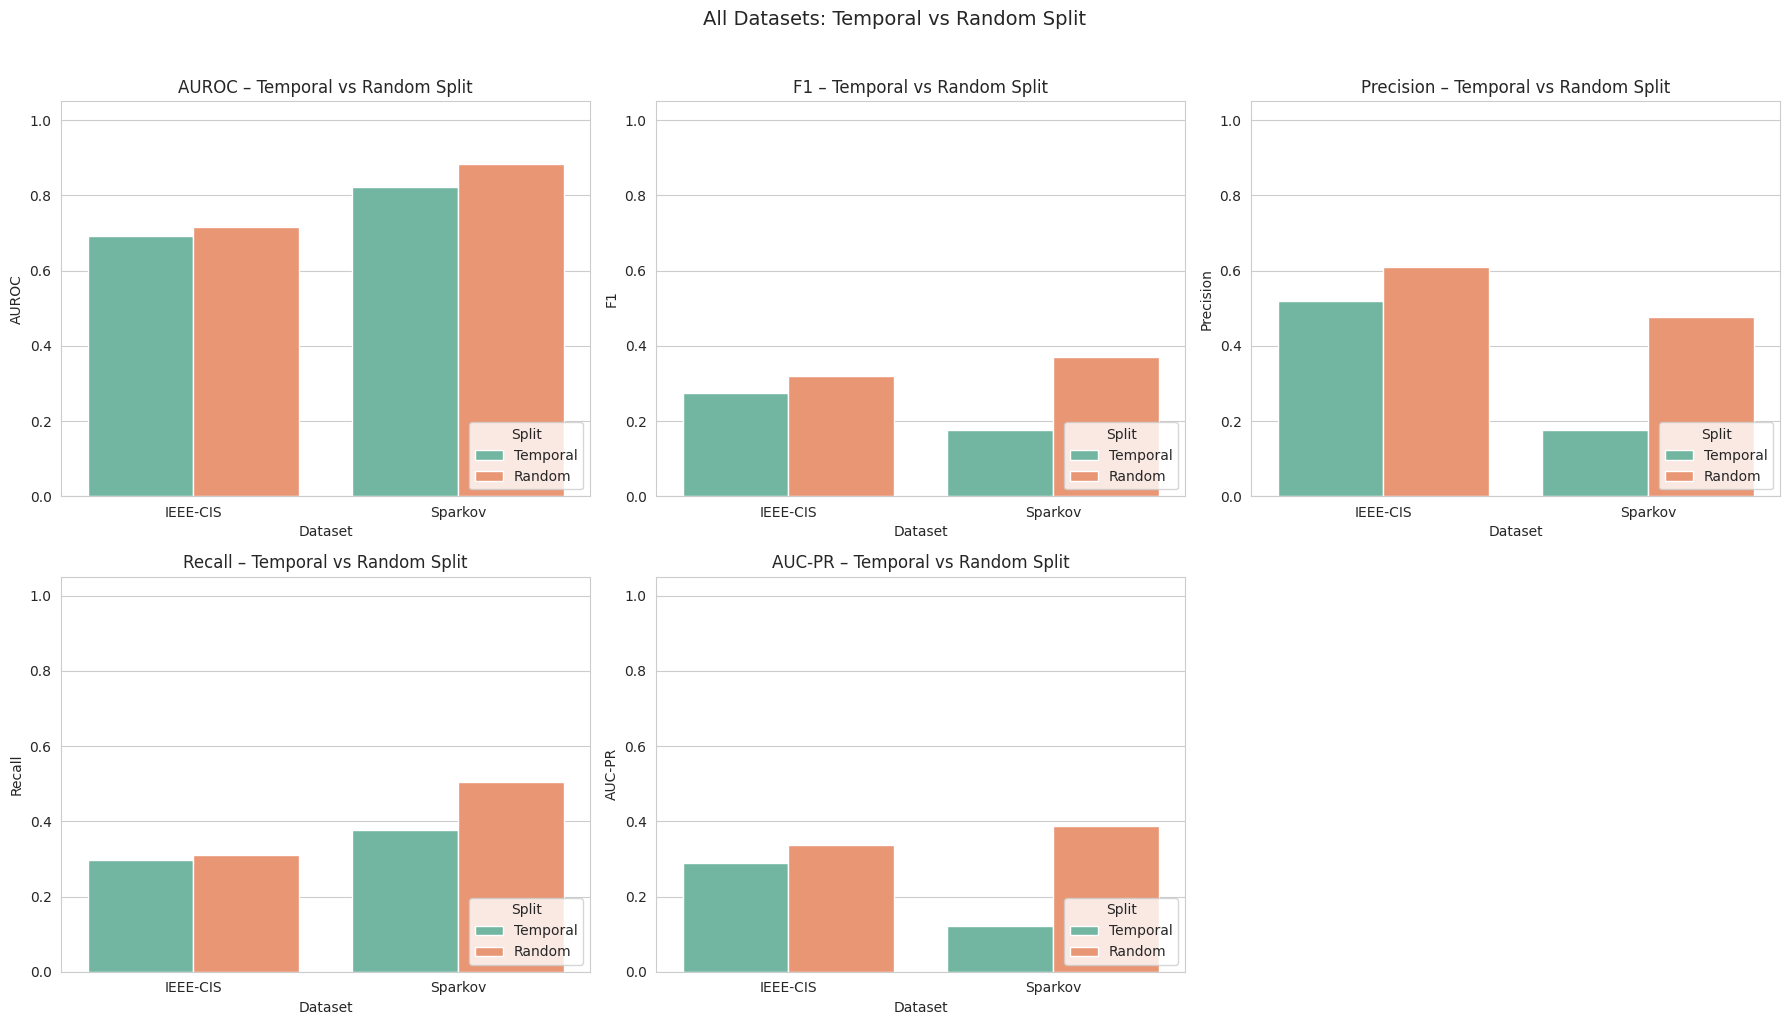

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, metric in enumerate(metrics_list):
    ax = axes[i]
    sns.barplot(data=all_res, x='Dataset', y=metric, hue='Split', ax=ax,
                palette='Set2', errorbar=None)
    ax.set_title(f'{metric} – Temporal vs Random Split')
    ax.set_ylim(0, 1.05)
    ax.legend(title='Split', loc='lower right')
# Hide last empty subplot
axes[-1].axis('off')
plt.suptitle("All Datasets: Temporal vs Random Split", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## Compact LaTeX‑style summary table

In [14]:
print("\n--- LaTeX‑friendly summary: F1 Inflation ---")
for dataset in ['IEEE-CIS', 'Sparkov']:
    sub = all_res[(all_res['Dataset'] == dataset)]
    for model in ['Logistic Regression', 'Random Forest', 'XGBoost']:
        temp_f1 = sub[(sub['Model'] == model) & (sub['Split'] == 'Temporal')]['F1'].values[0]
        rand_f1 = sub[(sub['Model'] == model) & (sub['Split'] == 'Random')]['F1'].values[0]
        if temp_f1 == 0:
            infl_str = "∞" if rand_f1 > 0 else "0"
        else:
            infl_str = f"{100*(rand_f1-temp_f1)/temp_f1:+.1f}\\%"
        print(f"  {dataset:15s} & {model:20s} & {temp_f1:.3f} & {rand_f1:.3f} & {infl_str} \\\\")

# Average F1 inflation across temporal datasets only
print("\n--- Average F1 Inflation (IEEE + Sparkov) ---")
for model in ['Logistic Regression', 'Random Forest', 'XGBoost']:
    infls = []
    for dataset in ['IEEE-CIS', 'Sparkov']:
        sub = all_res[(all_res['Dataset'] == dataset)]
        temp_f1 = sub[(sub['Model'] == model) & (sub['Split'] == 'Temporal')]['F1'].values[0]
        rand_f1 = sub[(sub['Model'] == model) & (sub['Split'] == 'Random')]['F1'].values[0]
        if temp_f1 > 0:
            infls.append(100 * (rand_f1 - temp_f1) / temp_f1)
    if infls:
        print(f"  {model:20s}: avg F1 inflation = {np.mean(infls):+.1f}%")
    else:
        print(f"  {model:20s}: all temporal F1 = 0 (infinite inflation)")


--- LaTeX‑friendly summary: F1 Inflation ---
  IEEE-CIS        & Logistic Regression  & 0.191 & 0.215 & +12.3\% \\
  IEEE-CIS        & Random Forest        & 0.313 & 0.380 & +21.2\% \\
  IEEE-CIS        & XGBoost              & 0.317 & 0.368 & +15.8\% \\
  Sparkov         & Logistic Regression  & 0.150 & 0.142 & -5.2\% \\
  Sparkov         & Random Forest        & 0.142 & 0.621 & +338.1\% \\
  Sparkov         & XGBoost              & 0.240 & 0.344 & +43.3\% \\

--- Average F1 Inflation (IEEE + Sparkov) ---
  Logistic Regression : avg F1 inflation = +3.5%
  Random Forest       : avg F1 inflation = +179.6%
  XGBoost             : avg F1 inflation = +29.5%
